# 05 — Correspondence Generation (Feature Matching)

Runs SIFT, SuperPoint+LightGlue, and RoMa on the scale-matched pairs from
Notebook 04, then saves raw match CSVs per pair per method.

Runs **three** matchers on the scale-matched pairs from Notebook 04, so you
have a real comparison for your evaluation report:

1. **SIFT** — classical baseline.
2. **SuperPoint + LightGlue** — fast, sparse, learned matcher (the originally
   planned core technique).
3. **RoMa** — dense, robust matcher (good for larger scale/viewpoint gaps).
4. **MINIMA** scaffold — modality-invariant matcher (edit its demo-script args
   per the current repo README before running).

All raw match CSVs get saved per pair per method; Notebook 06 automatically
picks whichever method gave the most inliers per pair.

**Memory-safety change in this version:** the "coarse" side of every pair
(TMC-2 or IIRS, whichever is the reference) was never downsampled in
Notebook 04 — it stays at its own full native resolution, which can be a
large strip and was crashing the runtime when loaded whole for matching.
Every matcher below now reads a **decimated** (GDAL-downsampled-on-read)
version capped at `MAX_MATCH_DIM` pixels on the long side for the actual
detection/matching step, then **rescales the resulting keypoints back** to
the original `fine_scaled_path` / `coarse_path` pixel grid immediately
after — so the saved CSVs mean exactly the same thing as before, and
Notebook 06 needs **no changes**.


In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import os, csv, math
import numpy as np
import cv2
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

DRIVE_ROOT = '/content/drive/MyDrive/26166_DATA'
OUT_ROOT   = f'{DRIVE_ROOT}/processed/matches'
os.makedirs(OUT_ROOT, exist_ok=True)

MAX_MATCH_DIM = 3000   # cap on long side for detection/matching; raise/lower if needed

with open(f'{DRIVE_ROOT}/processed/manifest_scalespace.csv') as f:
    pair_manifest = list(csv.DictReader(f))

for m in pair_manifest:
    print(m['pair'], '->', m['fine_scaled_path'], m['coarse_path'])


Mounted at /content/drive
ohrc_to_tmc2 -> /content/drive/MyDrive/26166_DATA/processed/scalespace/ohrc_to_tmc2/ohrc_level3.tif /content/drive/MyDrive/26166_DATA/processed/scalespace/ohrc_to_tmc2/tmc2_level0.tif
tmc2_to_iirs -> /content/drive/MyDrive/26166_DATA/processed/scalespace/tmc2_to_iirs/tmc2_level4.tif /content/drive/MyDrive/26166_DATA/processed/scalespace/tmc2_to_iirs/iirs_level0.tif


## 0. GPU check

In [2]:
import torch
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print('Runtime > Change runtime type > GPU, then re-run this cell.')


CUDA available: True
Tesla T4


## 1. Shared memory-safe loaders

`load_gray_capped` performs a **decimated read straight from disk** — GDAL
downsamples while reading, so the full-resolution array is never
materialized in Python. This is the fix for the crash.


In [3]:
def load_gray_capped(path, max_dim=MAX_MATCH_DIM):
    """Decimated read: returns (image_at_reduced_size, scale_factor) where
    scale_factor is how much to multiply pixel coordinates by to map back
    to this file's own full native resolution."""
    with rasterio.open(path) as src:
        h, w = src.height, src.width
        scale = max(1, -(-max(h, w) // max_dim))   # ceil division
        out_h, out_w = max(1, round(h / scale)), max(1, round(w / scale))
        img = src.read(1, out_shape=(out_h, out_w), resampling=Resampling.average)
    return img, scale

def load_gray_display(path, max_dim=1200):
    """For plotting only — smaller cap, doesn't need to return scale."""
    img, _ = load_gray_capped(path, max_dim=max_dim)
    return img

def ensure_rgb_png_capped(path, max_dim=MAX_MATCH_DIM):
    img, scale = load_gray_capped(path, max_dim=max_dim)
    rgb = np.stack([img] * 3, axis=-1)
    tmp_path = path.replace('.tif', '_rgb_capped.png')
    from PIL import Image
    Image.fromarray(rgb).save(tmp_path)
    return tmp_path, scale, img.shape   # shape = (h, w) at the capped resolution


## 2. Baseline — classical SIFT matching (capped reads)

In [4]:
def sift_match(img1, img2, ratio_thresh=0.75):
    sift = cv2.SIFT_create()
    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)
    if des1 is None or des2 is None:
        return np.empty((0, 2)), np.empty((0, 2)), []
    bf = cv2.BFMatcher()
    raw_matches = bf.knnMatch(des1, des2, k=2)
    good = [m for m, n in raw_matches if m.distance < ratio_thresh * n.distance]
    pts1 = np.array([kp1[m.queryIdx].pt for m in good])
    pts2 = np.array([kp2[m.trainIdx].pt for m in good])
    return pts1, pts2, good

sift_results = {}
for m in pair_manifest:
    img_fine, fine_scale = load_gray_capped(m['fine_scaled_path'])
    img_coarse, coarse_scale = load_gray_capped(m['coarse_path'])
    pts1, pts2, good = sift_match(img_fine, img_coarse)
    if len(pts1):
        pts1 = pts1 * fine_scale     # rescale back to fine_scaled_path's own full resolution
        pts2 = pts2 * coarse_scale   # rescale back to coarse_path's own full resolution
    sift_results[m['pair']] = (pts1, pts2)
    print(f"{m['pair']}: SIFT found {len(good)} candidate matches "
          f"(fine_scale={fine_scale}, coarse_scale={coarse_scale})")


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


ohrc_to_tmc2: SIFT found 40 candidate matches (fine_scale=4, coarse_scale=59)
tmc2_to_iirs: SIFT found 3 candidate matches (fine_scale=4, coarse_scale=1)


## 3. SuperPoint + LightGlue (capped reads)

In [5]:
!pip install -q git+https://github.com/cvg/LightGlue.git

from lightglue import LightGlue, SuperPoint
from lightglue.utils import load_image, rbd

device = 'cuda' if torch.cuda.is_available() else 'cpu'
sp_extractor = SuperPoint(max_num_keypoints=2048).eval().to(device)
lg_matcher = LightGlue(features='superpoint').eval().to(device)

def lightglue_match(img1_path, img2_path, max_dim=MAX_MATCH_DIM):
    p1, s1, _ = ensure_rgb_png_capped(img1_path, max_dim)
    p2, s2, _ = ensure_rgb_png_capped(img2_path, max_dim)

    image0 = load_image(p1).to(device)
    image1 = load_image(p2).to(device)

    feats0 = sp_extractor.extract(image0)
    feats1 = sp_extractor.extract(image1)
    matches01 = lg_matcher({'image0': feats0, 'image1': feats1})
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]

    matches = matches01['matches']
    pts1 = feats0['keypoints'][matches[..., 0]].cpu().numpy() * s1
    pts2 = feats1['keypoints'][matches[..., 1]].cpu().numpy() * s2
    scores = matches01.get('scores')
    scores = scores.cpu().numpy() if scores is not None else np.ones(len(pts1))
    return pts1, pts2, scores

lightglue_results = {}
for m in pair_manifest:
    pts1, pts2, scores = lightglue_match(m['fine_scaled_path'], m['coarse_path'])
    lightglue_results[m['pair']] = (pts1, pts2, scores)
    print(f"{m['pair']}: LightGlue produced {len(pts1)} matches")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 103.4 MB/s eta 0:00:00
Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to /root/.cache/torch/hub/checkpoints/superpoint_v1.pth


100%|██████████| 4.96M/4.96M [00:00<00:00, 164MB/s]


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /root/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth


100%|██████████| 45.3M/45.3M [00:00<00:00, 341MB/s]
/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


ohrc_to_tmc2: LightGlue produced 0 matches
tmc2_to_iirs: LightGlue produced 0 matches


## 4. RoMa — dense robust matcher (capped reads)

In [8]:
!pip install -q git+https://github.com/Parskatt/RoMa.git

from romatch import roma_outdoor
roma_model = roma_outdoor(device=device)

for module in roma_model.modules():
    if hasattr(module, 'use_custom_corr'):
        module.use_custom_corr = False

print('RoMa loaded (custom_corr disabled — using PyTorch fallback).')
print('RoMa loaded.')


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


2026-09-14 09:27:42.295 | INFO     | romatch.models.model_zoo.roma_models:roma_model:255 - Using coarse resolution (560, 560), and upsample res (864, 864)


RoMa loaded (custom_corr disabled — using PyTorch fallback).
RoMa loaded.


In [9]:
def roma_match(img1_path, img2_path, model, device, sample_n=5000, max_dim=MAX_MATCH_DIM):
    p1, s1, (h1, w1) = ensure_rgb_png_capped(img1_path, max_dim)
    p2, s2, (h2, w2) = ensure_rgb_png_capped(img2_path, max_dim)

    warp, certainty = model.match(p1, p2, device=device)
    matches, certainty_sampled = model.sample(warp, certainty, num=sample_n)
    kpts1, kpts2 = model.to_pixel_coordinates(matches, h1, w1, h2, w2)
    pts1 = kpts1.cpu().numpy() * s1
    pts2 = kpts2.cpu().numpy() * s2
    return pts1, pts2, certainty_sampled.cpu().numpy()

roma_results = {}
for m in pair_manifest:
    pts1, pts2, cert = roma_match(m['fine_scaled_path'], m['coarse_path'], roma_model, device)
    roma_results[m['pair']] = (pts1, pts2, cert)
    print(f"{m['pair']}: RoMa produced {len(pts1)} dense-sampled matches (mean certainty {cert.mean():.3f})")


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


ohrc_to_tmc2: RoMa produced 5000 dense-sampled matches (mean certainty 0.538)
tmc2_to_iirs: RoMa produced 5000 dense-sampled matches (mean certainty 0.890)


## 5. MINIMA — modality-invariant matcher

Check `https://github.com/LSXI7/MINIMA`'s current README for exact demo-script
arguments before running.


In [10]:
!git clone -q https://github.com/LSXI7/MINIMA.git /content/MINIMA
%cd /content/MINIMA
!pip install -q -r requirements.txt
# Adapt per the repo's current Quick Start, e.g.:
# !python demo.py --im1 <fine_scaled_path> --im2 <coarse_path> --matcher loftr \
#     --ckpt weights/minima_loftr.ckpt --out /content/minima_out
%cd /content


/content/MINIMA
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 110.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
/content


## 6. Visualize matches for one pair (decimated display, not full images)

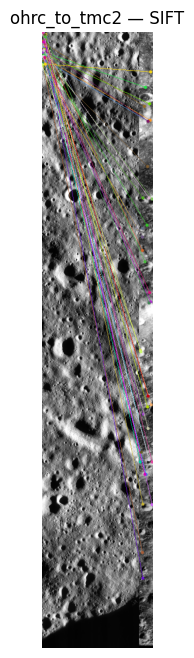

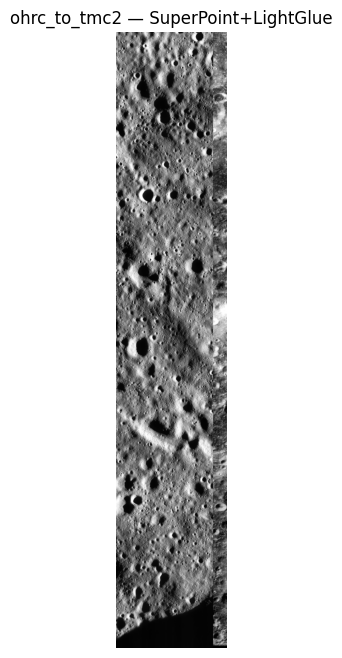

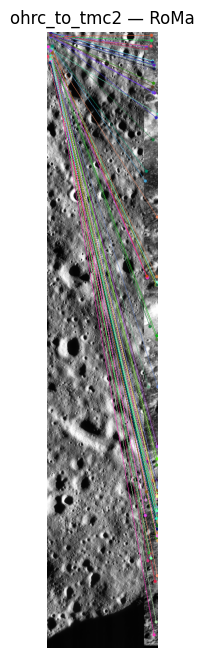

In [11]:
def draw_matches(img1, img2, pts1, pts2, display_scale=1.0, max_lines=100, title=''):
    """pts1/pts2 are in each image's OWN full-resolution coords; display_scale
    shrinks both the canvas and the point coordinates together for plotting."""
    h1, w1 = img1.shape; h2, w2 = img2.shape
    canvas = np.zeros((max(h1, h2), w1 + w2), dtype=np.uint8)
    canvas[:h1, :w1] = img1
    canvas[:h2, w1:w1 + w2] = img2
    canvas_rgb = cv2.cvtColor(canvas, cv2.COLOR_GRAY2BGR)

    idx = np.random.choice(len(pts1), size=min(max_lines, len(pts1)), replace=False) if len(pts1) else []
    for i in idx:
        p1 = tuple(np.round(pts1[i] * display_scale).astype(int))
        p2 = tuple(np.round(pts2[i] * display_scale).astype(int) + np.array([w1, 0]))
        color = tuple(np.random.randint(0, 255, 3).tolist())
        cv2.circle(canvas_rgb, p1, 3, color, -1)
        cv2.circle(canvas_rgb, p2, 3, color, -1)
        cv2.line(canvas_rgb, p1, p2, color, 1)

    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(canvas_rgb, cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis('off'); plt.show()

first_pair = pair_manifest[0]['pair']
first_m = [m for m in pair_manifest if m['pair'] == first_pair][0]

# decimated display copies + the scale used, so points (in native coords) plot correctly
img1_disp, disp_scale1 = load_gray_capped(first_m['fine_scaled_path'], max_dim=1200)
img2_disp, disp_scale2 = load_gray_capped(first_m['coarse_path'], max_dim=1200)
# use a single shared display_scale approximation (1/disp_scale) since both sides
# are being shown at roughly the same shrink factor here
disp_scale = 1.0 / max(disp_scale1, disp_scale2)

sp1, sp2 = sift_results[first_pair]
draw_matches(img1_disp, img2_disp, sp1, sp2, display_scale=disp_scale, title=f'{first_pair} — SIFT')

lp1, lp2, _ = lightglue_results[first_pair]
draw_matches(img1_disp, img2_disp, lp1, lp2, display_scale=disp_scale, title=f'{first_pair} — SuperPoint+LightGlue')

rp1, rp2, _ = roma_results[first_pair]
draw_matches(img1_disp, img2_disp, rp1, rp2, display_scale=disp_scale, title=f'{first_pair} — RoMa')


## 7. Save raw match points for every pair + method

In [12]:
def save_matches_csv(pts1, pts2, out_path, extra_cols=None):
    with open(out_path, 'w', newline='') as f:
        writer = csv.writer(f)
        header = ['x_fine', 'y_fine', 'x_coarse', 'y_coarse']
        if extra_cols: header += list(extra_cols.keys())
        writer.writerow(header)
        for i in range(len(pts1)):
            row = [pts1[i][0], pts1[i][1], pts2[i][0], pts2[i][1]]
            if extra_cols: row += [extra_cols[k][i] for k in extra_cols]
            writer.writerow(row)

for m in pair_manifest:
    pair = m['pair']
    out_dir = f'{OUT_ROOT}/{pair}'
    os.makedirs(out_dir, exist_ok=True)

    p1, p2 = sift_results[pair]
    save_matches_csv(p1, p2, f'{out_dir}/sift_raw_matches.csv')

    p1, p2, scores = lightglue_results[pair]
    save_matches_csv(p1, p2, f'{out_dir}/lightglue_raw_matches.csv', extra_cols={'score': scores})

    p1, p2, cert = roma_results[pair]
    save_matches_csv(p1, p2, f'{out_dir}/roma_raw_matches.csv', extra_cols={'certainty': cert})

    print(f"Saved raw match CSVs for {pair} "
          f"(SIFT: {len(sift_results[pair][0])}, "
          f"LightGlue: {len(lightglue_results[pair][0])}, "
          f"RoMa: {len(roma_results[pair][0])})")

print('\nRaw, unfiltered matches saved for all methods. Continue to 06_transform_and_warp.ipynb —')
print('it needs NO changes, since these CSVs are in the same coordinate frame as before.')


Saved raw match CSVs for ohrc_to_tmc2 (SIFT: 40, LightGlue: 0, RoMa: 5000)
Saved raw match CSVs for tmc2_to_iirs (SIFT: 3, LightGlue: 0, RoMa: 5000)

Raw, unfiltered matches saved for all methods. Continue to 06_transform_and_warp.ipynb —
it needs NO changes, since these CSVs are in the same coordinate frame as before.


---
### Notes
- All saved coordinates are still relative to `fine_scaled_path`'s and
  `coarse_path`'s own full native pixel grids — identical contract to
  before, so **Notebook 06 requires no edits**.
- If a crash still happens, lower `MAX_MATCH_DIM` (e.g. to 2000) at the top
  and re-run from Section 1 onward.
- Restart the runtime once before re-running this notebook, since a crashed
  session doesn't reliably free memory on its own.
